# 06-07 | Mittlere Höhe und begrenztes Rechenbudget

**Termin 06:** Fläche als Breite mal mittlere Höhe verstehen.
**Termin 07:** Stichprobenumfang planen und eine Simulation sicher begrenzen.
Beide Termine haben eigene Aufgaben und einen ausdrücklichen Haltepunkt.
Vorwissen: Mittelwert, Standardfehler, Funktionen und Seed aus Termin 05.
Die Basis ist vollständig ausführbar; eigene Antworten kommen in neue Zellen.
Kursumgebung mit NumPy, SciPy und Matplotlib; keine Downloads oder Dateien.

In [2]:
from random import Random
import math
from statistics import mean, median, stdev
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import quad
from scipy.stats import t

plt.rcParams.update({"font.size": 14})

## Termin 06: Erst feste Höhen

Die Höhen 1, 2, 3 haben Mittelwert 2. Bei Breite 2 ergibt das Fläche 4.
Dies ist eine Rechenprobe, noch keine Zufallsstichprobe.
`stdev` verwendet den Stichprobennenner N - 1. Der SE des Höhenmittels ist
diese Streuung geteilt durch sqrt(N); die Breite skaliert auch den SE.
Für einen geschätzten SE brauchen wir mindestens zwei Werte.

In [3]:
def auswertung_hoehen(hoehen, breite):
    if len(hoehen) < 2 or not math.isfinite(breite) or breite <= 0:
        raise ValueError("Mindestens zwei Hoehen und positive endliche Breite erforderlich")
    if not all(math.isfinite(wert) for wert in hoehen):
        raise ValueError("Hoehen muessen endlich sein")
    return {
        "anzahl": len(hoehen),
        "schaetzung": breite * mean(hoehen),
        "standardfehler": breite * stdev(hoehen) / math.sqrt(len(hoehen)),
    }


print("Rechenprobe:", auswertung_hoehen([1, 2, 3], 2))

Rechenprobe: {'anzahl': 3, 'schaetzung': 4, 'standardfehler': 1.1547005383792517}


## Ein vollständiger Lauf

Die Eingabe `funktion` ist eine Rechenregel: `funktion(0.25)` liefert eine
Höhe. Wir ziehen unabhängige gleichverteilte Stellen im Intervall, berechnen
ihre Höhen und mitteln. Für andere Ziehverteilungen reicht diese Formel
im Allgemeinen nicht. Die Breite ist rechts minus links.

In [4]:
def mc_integral(funktion, links, rechts, anzahl, seed):
    if anzahl < 2 or not math.isfinite(links) or not math.isfinite(rechts) or rechts <= links:
        raise ValueError("Mindestens zwei Ziehungen und ein endliches wachsendes Intervall erforderlich")
    generator = Random(seed)
    hoehen = []
    for versuch in range(anzahl):
        stelle = generator.uniform(links, rechts)
        hoehen.append(funktion(stelle))
    return auswertung_hoehen(hoehen, rechts - links)


def lineare_hoehe(stelle):
    return stelle


def wurzel_hoehe(stelle):
    return math.sqrt(stelle)


print("g(x)=x auf [0,1]:", mc_integral(lineare_hoehe, 0, 1, 1000, 2026))

g(x)=x auf [0,1]: {'anzahl': 1000, 'schaetzung': 0.4983659359955837, 'standardfehler': 0.008959753943541052}


`lineare_hoehe` ohne Klammern übergibt die Funktion; mit Klammern und Zahl
würden wir sie sofort auswerten. Für g(x)=x auf [0,1] ist die Fläche ein
Dreieck: 1 * 1 / 2 = 0.5. Diese Referenz brauchen Sie nicht herzuleiten.
Ein Aufruf liefert ein Dictionary mit N, Flächenschätzung und geschätztem SE.
Das Verfahren schätzt das Integral; bei negativen Höhen ist es eine
vorzeichenbehaftete Bilanz, nicht die gesamte geometrische Fläche.

## Ein Bild für g(x)=sqrt(x)

Die Kurve hat auf [0,1] die bekannte Referenzfläche 2/3. Der blaue Balken
markiert die mittlere Höhe aus 1000 gezogenen Stellen. Das Rechteck darunter
hat dieselbe geschätzte Fläche: Breite 1 mal mittlere Höhe.
Die ersten 20 gezogenen Höhen sind als Punkte sichtbar. Grafikcode ist
vorbereitet; Sie müssen ihn nicht nachprogrammieren.

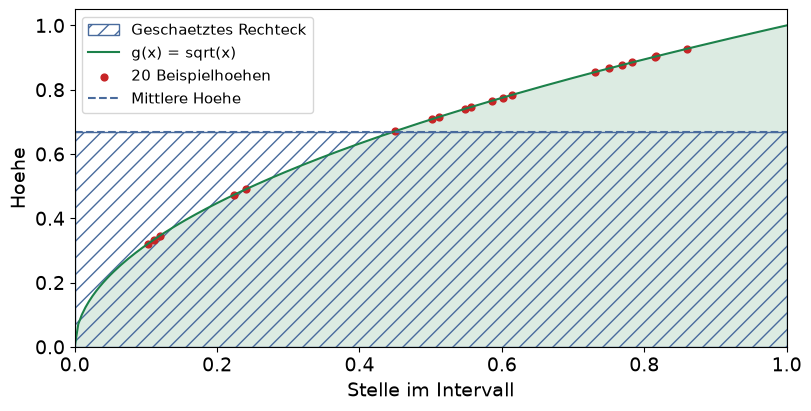

Wurzellauf: {'anzahl': 1000, 'schaetzung': 0.6669953157279908, 'standardfehler': 0.007316879219586424} Referenz: 0.6666666666666666


In [5]:
generator = Random(2026)
stellen = []
hoehen = []
for versuch in range(1000):
    stelle = generator.uniform(0, 1)
    stellen.append(stelle)
    hoehen.append(wurzel_hoehe(stelle))
kurvenstellen = np.linspace(0, 1, 201)
figur, achse = plt.subplots(figsize=(8, 4), layout="constrained")
achse.fill_between(kurvenstellen, np.sqrt(kurvenstellen), color="#dcebe2")
achse.fill_between([0, 1], [mean(hoehen), mean(hoehen)],
                  facecolor="none", edgecolor="#496b9d", hatch="//", label="Geschaetztes Rechteck")
achse.plot(kurvenstellen, np.sqrt(kurvenstellen), color="#1c814a", label="g(x) = sqrt(x)")
achse.scatter(stellen[:20], hoehen[:20], color="#c72426", s=24, label="20 Beispielhoehen")
achse.axhline(mean(hoehen), color="#496b9d", linestyle="--", label="Mittlere Hoehe")
achse.set(xlim=(0, 1), ylim=(0, 1.05), xlabel="Stelle im Intervall", ylabel="Hoehe")
achse.legend(loc="upper left", fontsize=11)
plt.show()
plt.close(figur)
print("Wurzellauf:", auswertung_hoehen(hoehen, 1), "Referenz:", 2 / 3)

## Dieselben Daten als Array

Eine NumPy-Arrayoperation bearbeitet alle Einträge. `np.sqrt` berechnet die
Wurzel elementweise; `np.mean` mittelt danach. `shape` ist die Form, hier
(1000,): genau eine Achse mit 1000 Einträgen, keine 1000 vollständigen Läufe.
Wir verwenden dieselben Stellen, damit nur die Rechenform verglichen wird.
Ein anderer Generatortyp muss trotz gleicher Seedzahl nicht dieselben Werte liefern.

In [6]:
array_stellen = np.asarray(stellen)
array_hoehen = np.sqrt(array_stellen)
print("Form:", array_stellen.shape)
print("Array-Mittelwert:", float(np.mean(array_hoehen)))
print("Gleiche Rechnung bis auf Rundung:", math.isclose(float(np.mean(array_hoehen)), mean(hoehen)))
print("Array-SE:", float(np.std(array_hoehen, ddof=1) / np.sqrt(len(array_hoehen))))

Form: (1000,)
Array-Mittelwert: 0.6669953157279909
Gleiche Rechnung bis auf Rundung: True
Array-SE: 0.007316879219586424


## Eigenarbeit 06 | 30 Minuten

**A06.1 | 15 Minuten:** Feste Höhen [0.2, 0.4, 0.6, 0.8], Intervallbreite 3.
Berechnen Sie Mittelwert und Flächenschätzung von Hand und prüfen Sie mit
`auswertung_hoehen`. Warum ist die Fläche nicht einfach der Mittelwert?
Warum ist diese vorbereitete Liste allein kein Genauigkeitsnachweis?

**A06.2 | 15 Minuten:** Schätzen Sie die Fläche unter sqrt(x) auf [0,1]
für N=1000 und N=4000, jeweils mit Seed 11 und 12. Notieren Sie N, Seed,
Schätzung, SE und Abweichung zur Referenz 2/3. Vergleichen Sie den typischen
SE-Trend mit der zufälligen Abweichung jedes einzelnen Laufs.
**Hilfe:** `mc_integral(wurzel_hoehe, 0, 1, 1000, 11)` ist der erste Aufruf.
Vier einzelne Aufrufe sind erlaubt; eine verschachtelte Schleife ist keine Pflicht.
Die Argumente bedeuten Rechenregel, linke Grenze, rechte Grenze, Anzahl, Seed.
`wurzel_hoehe` ohne Klammern übergibt die Regel. Speichern Sie den Aufruf
als `ergebnis`; `ergebnis["schaetzung"]` und `ergebnis["standardfehler"]`
liefern die zwei Kennzahlen. `abs(ergebnis["schaetzung"] - 2/3)` ist die Abweichung.

**Drei Dinge bleiben:** gleichverteilte Stellen, mittlere Funktionshöhe,
Breite als Faktor auch beim SE. Ein beliebiger Sampler schätzt nicht
automatisch die Fläche. Eine bekannte Referenz hilft beim Prüfen.

## Halt: Hier endet Termin 06

Im nächsten Termin planen wir N vorab und begrenzen die Laufzeit einer
Simulation. Die Vertiefung zu weiteren Integranden steht am Notebookende.
Nicht alles an einem Termin bearbeiten.

## Termin 07: Aus einem Pilotlauf planen

Nach einem Kernelneustart zuerst den Abschnitt 06 bis zu seinem Haltepunkt
ausführen, damit Funktionen und Importe vorhanden sind. Die Wahlteile am
Notebookende brauchen Sie dafür nicht.

Bei unveränderter Verteilung skaliert der typische SE wie 1/sqrt(N).
Für ein Ziel SE <= ziel_se planen wir N_neu = aufrunden(N_alt * (SE_alt/Ziel)^2).
Das ist eine Prognose aus geschätzter Streuung, keine Genauigkeitsgarantie.
Wir planen mindestens den Pilotumfang. Nullstreuung im Pilot erlaubt diese
Planung nicht: Vielleicht wurde ein seltenes Ereignis noch nicht beobachtet.

In [7]:
auswertung_hoehen([0.2, 0.4,0.6,0.8],3)


{'anzahl': 4, 'schaetzung': 1.5, 'standardfehler': 0.3872983346207417}

In [8]:
def plane_anzahl(pilot_anzahl, pilot_se, ziel_se):
    if pilot_anzahl < 2 or not math.isfinite(pilot_se) or not math.isfinite(ziel_se):
        raise ValueError("Gueltiger Pilotumfang und endliche SE-Werte erforderlich")
    if pilot_se <= 0 or ziel_se <= 0:
        raise ValueError("Pilot-SE und Ziel-SE muessen positiv sein")
    return max(pilot_anzahl, math.ceil(pilot_anzahl * (pilot_se / ziel_se) ** 2))


print("Planung aus N=100, SE=0.04, Ziel=0.01:", plane_anzahl(100, 0.04, 0.01))

Planung aus N=100, SE=0.04, Ziel=0.01: 1600


**Vorhersage:** Warum steht das Verhältnis der Standardfehler im Quadrat?
Ein Viertel des SE braucht bei gleicher Verteilung etwa 16-mal so viele Werte.
Die alte Beispielrechnung N=100, SE=22 und Ziel SE <= 2 liefert 12100.
Für die strengere Modellforderung SE < 2 wäre die kleinste ganze Zahl 12101.
Geschätzte Pilotwerte liefern trotzdem keine Garantie für den späteren SE.

## SE-Ziel und Intervallhalbbreite sind nicht dasselbe

[0.60, 0.70] hat Mitte 0.65, Halbbreite 0.05 und ganze Breite 0.10.
Für ein großes, vorab festgelegtes N verwenden wir näherungsweise
Halbbreite h = 1.96 * SE. Für h <= 0.02 planen wir daher mit
SE-Ziel 0.02 / 1.96, nicht 0.02. Ein t-Intervall hat einen von N abhängigen
Faktor; 1.96 ist hier eine Planungsnäherung für ausreichend große N.
Pilot und endgültiger Lauf erhalten verschiedene Zufallsfolgen.

In [9]:
pilot = mc_integral(wurzel_hoehe, 0, 1, 200, 2026)
geplant = plane_anzahl(pilot["anzahl"], pilot["standardfehler"], 0.005)
endgueltiger_lauf = mc_integral(wurzel_hoehe, 0, 1, geplant, 2027)
print("Pilot:", pilot)
print("Geplanter neuer Umfang:", geplant)
print("Neuer Lauf:", endgueltiger_lauf)
print("Gesamtkosten mit Pilot:", pilot["anzahl"] + geplant)

Pilot: {'anzahl': 200, 'schaetzung': 0.6814002347360895, 'standardfehler': 0.016021797124309168}
Geplanter neuer Umfang: 2054
Neuer Lauf: {'anzahl': 2054, 'schaetzung': 0.6637734286660895, 'standardfehler': 0.005175964981182367}
Gesamtkosten mit Pilot: 2254


## Begrenzte Batches

Ein Batch ist ein Paket weiterer Funktionswerte. Das folgende Verfahren
ist eine **Alternative** zur vorigen Pilot-Hauptlauf-Planung, kein dritter
Lauf, der anschließend noch nötig wäre. Es demonstriert eine sichere
Arbeitsgrenze, nicht ein nach beliebigem Stoppen gültiges 95%-Intervall.

`min_anzahl` verhindert eine Entscheidung nach sehr wenigen Beobachtungen.
`max_anzahl` begrenzt die Arbeit auch dann, wenn das Ziel nicht erreicht wird.
Der letzte Batch darf kleiner sein. Der Generator läuft durchgehend weiter.
Null beobachtete Streuung wird hier vorsichtshalber nicht als Zielerreichung
gewertet. Es werden keine 95%-Intervalle für diesen adaptiven Stopp ausgegeben.

In [10]:
def batch_integral(funktion, links, rechts, ziel_se, min_anzahl, max_anzahl, batchgroesse, seed):
    if min_anzahl < 2 or max_anzahl < min_anzahl or batchgroesse <= 0:
        raise ValueError("Gueltige Mindestzahl, Maximalzahl und positive Batchgroesse erforderlich")
    if not math.isfinite(ziel_se) or ziel_se <= 0:
        raise ValueError("Ziel-SE muss positiv und endlich sein")
    if not math.isfinite(links) or not math.isfinite(rechts) or rechts <= links:
        raise ValueError("Endliches wachsendes Intervall erforderlich")
    generator = Random(seed)
    hoehen = []
    verlauf = []
    while len(hoehen) < max_anzahl:
        rest = max_anzahl - len(hoehen)
        for versuch in range(min(batchgroesse, rest)):
            hoehen.append(funktion(generator.uniform(links, rechts)))
        if len(hoehen) >= min_anzahl:
            ergebnis = auswertung_hoehen(hoehen, rechts - links)
            verlauf.append(ergebnis)
            if 0 < ergebnis["standardfehler"] <= ziel_se:
                return {**ergebnis, "status": "SE-Ziel beobachtet", "verlauf": verlauf}
    return {**ergebnis, "status": "Budget erreicht", "verlauf": verlauf}


batch_demo = batch_integral(wurzel_hoehe, 0, 1, 0.01, 200, 2000, 100, 2026)
print("Batch-Ergebnis:", batch_demo["anzahl"], batch_demo["schaetzung"], batch_demo["status"])

Batch-Ergebnis: 600 0.6786322600390506 SE-Ziel beobachtet


`while` wiederholt, solange die Bedingung wahr ist. `rest` ist das verbleibende
Budget. `min(batchgroesse, rest)` verhindert ein Überschreiten im letzten Batch.
Der eingerückte `if`-Block prüft erst ab der Mindestzahl. `return` beendet
den gesamten Funktionsaufruf, nicht nur den aktuellen Batch.
`**ergebnis` übernimmt vorhandene benannte Werte in ein neues Dictionary.
`verlauf` enthält ausschließlich die bereits ausgewerteten Zwischenstände.

**Wichtig:** "SE-Ziel beobachtet" ist keine Schranke für den wahren Fehler.
Wiederholtes Nachsehen und ergebnisabhängiges Stoppen verändern die
statistische Situation. Wir behaupten dafür keine feste 95%-Deckung.
Für bestätigende Berichte vorzugsweise vorab festes N oder ein begründetes
sequenzielles Verfahren nutzen; ein neuer Lauf nach Pilotplanung ist ein eigener Schritt.

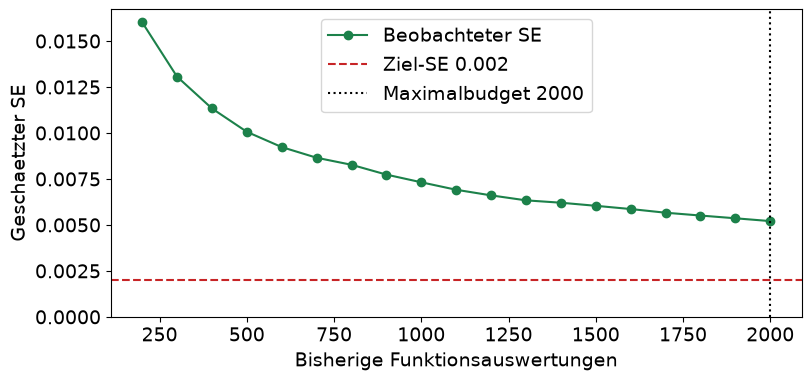

Strenger Lauf: 2000 Budget erreicht


In [11]:
strenger_lauf = batch_integral(wurzel_hoehe, 0, 1, 0.002, 200, 2000, 100, 2026)
umfang = []
fehler = []
for zwischenstand in strenger_lauf["verlauf"]:
    umfang.append(zwischenstand["anzahl"])
    fehler.append(zwischenstand["standardfehler"])
figur, achse = plt.subplots(figsize=(8, 3.7), layout="constrained")
achse.plot(umfang, fehler, marker="o", color="#1c814a", label="Beobachteter SE")
achse.axhline(0.002, linestyle="--", color="#c72426", label="Ziel-SE 0.002")
achse.axvline(2000, linestyle=":", color="black", label="Maximalbudget 2000")
achse.set(xlabel="Bisherige Funktionsauswertungen", ylabel="Geschaetzter SE", ylim=(0, None))
achse.legend()
plt.show()
plt.close(figur)
print("Strenger Lauf:", strenger_lauf["anzahl"], strenger_lauf["status"])

## Eigenarbeit 07 | 30 Minuten

**A07.1 | 15 Minuten:** Ein Pilot hat N=100 und SE=0.06. Planen Sie zuerst
für SE <= 0.02, danach für eine angenäherte 95%-Intervallhalbbreite <= 0.02.
Warum unterscheiden sich die Umfänge? Zählen Sie die Pilotkosten separat.
**Hilfe:** Im zweiten Fall zuerst das SE-Ziel durch Division durch 1.96 bestimmen.
Taschenrechner ist erlaubt; Zwischenergebnisse nicht vorzeitig runden.

**A07.2 | 15 Minuten:** Führen Sie die vorbereitete Batch-Schleife mit
sqrt(x), Intervall [0,1], Ziel-SE 0.000001, Mindestzahl 400, Maximalzahl 1250,
Batchgröße 200 und Seed 2026 aus. Erklären Sie den letzten Batch und den Status.
Ergänzen Sie die Ausgabe um das Restbudget und die Zahl der ausgewerteten
Zwischenstände. Welche Codezeile verhindert ein Überschreiten?
**Hilfe:** Verwenden Sie die Schlüssel `"anzahl"`, `"status"` und `"verlauf"`.
Kopieren Sie diesen Aufruf in eine eigene Zelle; die Zahlen sind die
Aufgabeneingaben, nicht bereits die berechneten Ergebnisse:
```python
ergebnis = batch_integral(
    wurzel_hoehe, 0, 1, ziel_se=0.000001,
    min_anzahl=400, max_anzahl=1250, batchgroesse=200, seed=2026,
)
```
Notieren Sie vor dem Ausführen, welche Grenze der Lauf nicht überschreiten darf.
Die Zahl aller Batches und die Zahl der ausgewerteten Zwischenstände sind
bei einer Mindestzahl oberhalb der Batchgröße nicht dasselbe.

**Drei Dinge bleiben:** Umfang quadratisch planen; SE-Ziel und Halbbreite
trennen; Mindestumfang, Maximalbudget und ehrlichen Abbruchstatus angeben.
**Abschlussfrage:** Belegt ein kleiner beobachteter SE einen kleinen Modellfehler?
Nein. Im nächsten Termin untersuchen wir deshalb die Eingabeannahmen.

## Halt: Hier endet Termin 07

## Wahlteil: Weitere Integranden und eine Sampler-Schnittstelle

Hier greifen wir die ursprüngliche Übung 1 auf. `mc_erwartung` nimmt
eine Arrayfunktion und eine Ziehfunktion. Die Ziehfunktion bekommt den
Generator explizit; jede Funktion liefert genau N Werte. Geschätzt wird
der Erwartungswert unter dieser Verteilung, nicht automatisch ein Integral.
Uniform auf [a,b] braucht für das Integral weiterhin den Faktor b-a.

`np.sinc(x)` ist bereits sin(pi*x)/(pi*x), einschließlich sinc(0)=1.
Es ist nicht die unnormierte Funktion sin(x)/x.

In [12]:
def uniform_sampler(generator, anzahl):
    return generator.uniform(0, 1, size=anzahl)


def gauss_array(stellen):
    return np.exp(-(stellen ** 2))


def mc_erwartung(funktion, sampler, anzahl, generator):
    if anzahl < 2:
        raise ValueError("Mindestens zwei Ziehungen erforderlich")
    ziehungen = np.asarray(sampler(generator, anzahl))
    werte = np.asarray(funktion(ziehungen))
    if ziehungen.shape != (anzahl,) or werte.shape != (anzahl,):
        raise ValueError("Sampler und Funktion muessen je N eindimensionale Werte liefern")
    return auswertung_hoehen(werte.tolist(), 1)


gauss_referenz, quadratur_fehler = quad(lambda stelle: math.exp(-stelle ** 2), 0, 1)
sinc_referenz, sinc_quad_fehler = quad(lambda stelle: float(np.sinc(stelle)), 0, 1)
integranden = [("sqrt", np.sqrt, 2 / 3), ("exp(-x^2)", gauss_array, gauss_referenz),
               ("normierte sinc", np.sinc, sinc_referenz)]
print("sinc(0):", float(np.sinc(0)))
for name, funktion, referenz in integranden:
    for anzahl in [1000, 10000, 100000]:
        ergebnis = mc_erwartung(funktion, uniform_sampler, anzahl, np.random.default_rng(2026))
        halbbreite = float(t.ppf(0.975, df=anzahl - 1)) * ergebnis["standardfehler"]
        print(name, anzahl, "Schaetzung", round(ergebnis["schaetzung"], 6),
              "SE", round(ergebnis["standardfehler"], 6),
              "95%-Intervall naeherungsweise", round(ergebnis["schaetzung"] - halbbreite, 6),
              round(ergebnis["schaetzung"] + halbbreite, 6), "Referenz", round(referenz, 6))
print("Quadratur-Fehlerschaetzungen:", quadratur_fehler, sinc_quad_fehler)

sinc(0): 1.0
sqrt 1000 Schaetzung 0.684932 SE 0.007265 95%-Intervall naeherungsweise 0.670675 0.699188 Referenz 0.666667
sqrt 10000 Schaetzung 0.671618 SE 0.00233 95%-Intervall naeherungsweise 0.66705 0.676186 Referenz 0.666667
sqrt 100000 Schaetzung 0.665202 SE 0.000747 95%-Intervall naeherungsweise 0.663738 0.666665 Referenz 0.666667
exp(-x^2) 1000 Schaetzung 0.732331 SE 0.006342 95%-Intervall naeherungsweise 0.719885 0.744776 Referenz 0.746824
exp(-x^2) 10000 Schaetzung 0.743433 SE 0.002016 95%-Intervall naeherungsweise 0.73948 0.747385 Referenz 0.746824
exp(-x^2) 100000 Schaetzung 0.747981 SE 0.000636 95%-Intervall naeherungsweise 0.746735 0.749227 Referenz 0.746824
normierte sinc 1000 Schaetzung 0.566119 SE 0.010163 95%-Intervall naeherungsweise 0.546176 0.586063 Referenz 0.58949
normierte sinc 10000 Schaetzung 0.584081 SE 0.003232 95%-Intervall naeherungsweise 0.577746 0.590417 Referenz 0.58949
normierte sinc 100000 Schaetzung 0.591357 SE 0.001019 95%-Intervall naeherungsweise 0.

Die t-Intervalle sind für diese nichtnormalen Höhen bei großem festem N
Näherungen, keine exakten Garantien. `quad` verwendet adaptive Quadratur:
für diese glatten eindimensionalen Funktionen ist sie meist geeigneter als MC.
Ihr geschätzter numerischer Fehler ist kein statistischer SE.
Auch Quadratur kann bei Singularitäten oder unbemerkten schmalen Spitzen versagen.
Gleiche Seedzahlen in dieser Tabelle erzeugen verschachtelte Daten je Integrand;
die Zeilen sind keine unabhängigen Replikationen und keine Deckungsstudie.

## Wahlteil: Laufzeiten wirklich messen

Pro Funktion und N werden drei Zeiten mit `perf_counter` gemessen; berichtet
wird ihr Median in Sekunden. Enthalten sind Ziehung, Funktionsauswertung und
Zusammenfassung, nicht Grafik oder Notebookstart. Rechnerlast und Umgebung
verändern die Zeiten. Es gibt keinen garantierten Geschwindigkeitsfaktor.
Nur diese ausdrücklich markierte Zeitmessungszelle ist vom Vergleich identischer
Ausgabetexte ausgenommen; sie wird trotzdem in jedem frischen Lauf ausgeführt.

In [13]:
for name, funktion, referenz in integranden:
    for anzahl in [1000, 10000, 100000]:
        messzeiten = []
        for wiederholung in range(3):
            startzeit = perf_counter()
            mc_erwartung(funktion, uniform_sampler, anzahl, np.random.default_rng(2026))
            messzeiten.append(perf_counter() - startzeit)
        print(name, anzahl, "Median Sekunden:", round(median(messzeiten), 6))

sqrt 1000 Median Sekunden: 0.001954
sqrt 10000 Median Sekunden: 0.016977
sqrt 100000 Median Sekunden: 0.134991
exp(-x^2) 1000 Median Sekunden: 0.002343
exp(-x^2) 10000 Median Sekunden: 0.018298
exp(-x^2) 100000 Median Sekunden: 0.137556
normierte sinc 1000 Median Sekunden: 0.001597
normierte sinc 10000 Median Sekunden: 0.012978
normierte sinc 100000 Median Sekunden: 0.133721


## Wahlteil: Formen, Speicher und größere Modelle

Broadcasting kombiniert kompatible Arrayformen ohne ausgeschriebene Schleife.
Unten wird (2,1) mit (1,3) kombiniert; das Ergebnis hat (2,3). Große Formen
können entsprechend viel Speicher brauchen. `empty` reserviert Speicher,
initialisiert ihn aber nicht sinnvoll: Jeder Eintrag muss vor Nutzung beschrieben werden.

In [14]:
spaltenwerte = np.array([[1], [2]])
zeilenwerte = np.array([[10, 20, 30]])
print("Broadcasting:", (spaltenwerte + zeilenwerte).shape)
vorbelegt = np.empty(4)
for position in range(4):
    vorbelegt[position] = position ** 2
print("Vollstaendig beschriebener Speicher:", vorbelegt)

Broadcasting: (2, 3)
Vollstaendig beschriebener Speicher: [0. 1. 4. 9.]


Unsere Batch-Demo behält alle Höhen und berechnet die Streuung erneut.
Sie ist leicht lesbar, aber kein speicherkonstantes Streaming-Verfahren.
Für große Daten braucht man stabile Online-/Batch-Momente und eigene
Tests; wiederholt sum(x*x) - sum(x)^2/N ist bei nahen großen Zahlen instabil.
Profiling untersucht danach, welche Funktionen die Zeit verbrauchen;
die obige Stoppuhr lokalisiert solche Ursachen noch nicht.
Eine vollständige Streaming-/Profiling-Vertiefung bleibt im Projektteil offen.

Für ein mehrdimensionales gleichverteiltes Rechteckmodell ersetzt das
Rechteckvolumen die Breite. In [0,2] x [0,3] ist es beispielsweise 6.
Ein Trefferanteil 0.4 entspräche geschätztem Teilvolumen 2.4, nicht 0.4.
Relative Präzision SE/abs(Schätzung) ist nahe null instabil; dann ein
fachlich sinnvolles absolutes Ziel angeben statt durch fast null zu teilen.

In [15]:
# A06.1
hoehen_a061 = [0.2, 0.4, 0.6, 0.8]
ergebnis_a061 = auswertung_hoehen(hoehen_a061, 3)
print("Mittelwert der Hoehen:", mean(hoehen_a061))
print("Flaechenschaetzung:", ergebnis_a061["schaetzung"])
print("Geschaetzter SE der Flaeche:", ergebnis_a061["standardfehler"])


Mittelwert der Hoehen: 0.5
Flaechenschaetzung: 1.5
Geschaetzter SE der Flaeche: 0.3872983346207417


In [16]:
# A06.2
referenz_a062 = 2 / 3
for anzahl_a062 in [1000, 4000]:
    for seed_a062 in [11, 12]:
        ergebnis_a062 = mc_integral(wurzel_hoehe, 0, 1, anzahl_a062, seed_a062)
        abweichung_a062 = abs(ergebnis_a062["schaetzung"] - referenz_a062)
        print(
            "N =", anzahl_a062,
            "Seed =", seed_a062,
            "Schaetzung =", round(ergebnis_a062["schaetzung"], 6),
            "SE =", round(ergebnis_a062["standardfehler"], 6),
            "Abweichung =", round(abweichung_a062, 6),
        )


N = 1000 Seed = 11 Schaetzung = 0.673273 SE = 0.007365 Abweichung = 0.006607
N = 1000 Seed = 12 Schaetzung = 0.671124 SE = 0.007314 Abweichung = 0.004458
N = 4000 Seed = 11 Schaetzung = 0.66553 SE = 0.003717 Abweichung = 0.001137
N = 4000 Seed = 12 Schaetzung = 0.668942 SE = 0.003725 Abweichung = 0.002275


In [17]:
# A07.1
pilot_anzahl_a071 = 100
pilot_se_a071 = 0.06
umfang_se_a071 = plane_anzahl(pilot_anzahl_a071, pilot_se_a071, 0.02)
ziel_se_halbbreite_a071 = 0.02 / 1.96
umfang_halbbreite_a071 = plane_anzahl(
    pilot_anzahl_a071, pilot_se_a071, ziel_se_halbbreite_a071
)
print("N_neu fuer SE <= 0.02:", umfang_se_a071)
print("Pilotkosten:", pilot_anzahl_a071)
print("Gesamt mit Pilot:", pilot_anzahl_a071 + umfang_se_a071)
print("SE-Ziel fuer Halbbreite <= 0.02:", ziel_se_halbbreite_a071)
print("N_neu fuer Halbbreite <= 0.02:", umfang_halbbreite_a071)
print("Gesamt mit Pilot:", pilot_anzahl_a071 + umfang_halbbreite_a071)


N_neu fuer SE <= 0.02: 900
Pilotkosten: 100
Gesamt mit Pilot: 1000
SE-Ziel fuer Halbbreite <= 0.02: 0.010204081632653062
N_neu fuer Halbbreite <= 0.02: 3458
Gesamt mit Pilot: 3558


In [18]:
# A07.2
max_anzahl_a072 = 1250
batchgroesse_a072 = 200
ergebnis_a072 = batch_integral(
    wurzel_hoehe, 0, 1, ziel_se=0.000001,
    min_anzahl=400, max_anzahl=max_anzahl_a072,
    batchgroesse=batchgroesse_a072, seed=2026,
)
restbudget_a072 = max_anzahl_a072 - ergebnis_a072["anzahl"]
batches_a072 = math.ceil(ergebnis_a072["anzahl"] / batchgroesse_a072)
print("Auswertungen:", ergebnis_a072["anzahl"])
print("Schaetzung:", ergebnis_a072["schaetzung"])
print("SE:", ergebnis_a072["standardfehler"])
print("Status:", ergebnis_a072["status"])
print("Restbudget:", restbudget_a072)
print("Ausgewertete Zwischenstaende:", len(ergebnis_a072["verlauf"]))
print("Batches insgesamt:", batches_a072)


Auswertungen: 1250
Schaetzung: 0.673015667970579
SE: 0.006488422776197027
Status: Budget erreicht
Restbudget: 0
Ausgewertete Zwischenstaende: 6
Batches insgesamt: 7
